# Dalitz-plot analysis

This notebook studies the internal three-body kinematics of selected B -> KKK candidates with Dalitz variables. Dalitz plots are a standard tool for visualising resonant substructure and phase-space population in multibody decays.


## Physics motivation

For a three-body decay, two independent pairwise invariant masses fully describe the event position in phase space, up to angular information. Localised structures or bands in a Dalitz plot can indicate intermediate resonances, interference patterns, or non-uniform detector/selection effects.


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep the matplotlib font cache inside the project so notebook runs stay quiet
# even when the default cache directory is not writable.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "B2HHH_MagnetDown.root"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

DATA_PATH

PosixPath('/Volumes/USB128/lhcb-b2hhh-analysis/data/raw/B2HHH_MagnetDown.root')

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from src.physics.selection import load_b2hhh_dataframe, add_b_mass, apply_baseline_selection
from src.physics.dalitz import (
    OPPOSITE_SIGN_HIGH,
    OPPOSITE_SIGN_LOW,
    SAME_SIGN,
    compute_charge_ordered_dalitz_variables,
    compute_dalitz_variables,
)
from src.plotting.mass_plots import set_hep_style

set_hep_style()

Matplotlib is building the font cache; this may take a moment.


## Load and select candidates

The notebook uses the same ROOT input, B-mass reconstruction, and baseline selection as the rest of the project. This makes the Dalitz distributions directly comparable to the mass and CP-asymmetry studies.


In [3]:
df = load_b2hhh_dataframe(DATA_PATH)
df = add_b_mass(df)
df_sel = apply_baseline_selection(df)

print(f"Loaded candidates:   {len(df):,}")
print(f"Selected candidates: {len(df_sel):,}")
df_sel.head()


Loaded candidates:   5,135,823
Selected candidates: 1,645


,H1_PX,H1_PY,H1_PZ,H2_PX,H2_PY,H2_PZ,H3_PX,H3_PY,H3_PZ,H1_Charge,...,H3_Charge,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_VertexChi2,B_FlightDistance,B_mass
5911,409.597326,-922.895885,20897.310967,1203.071583,-1920.154667,40475.734267,-3459.363958,-2564.626154,75809.047870,-1,...,1,0.922096,0.950725,0.921754,0.059316,0.254305,0.092939,1.044176,53.008846,5278.782080
7561,1896.131812,342.165476,13004.358365,-212.269027,2315.053951,29215.421432,3919.152618,2803.269146,50026.628572,-1,...,1,0.803463,0.769137,0.964152,0.094286,0.038924,0.132662,1.234878,25.028023,5280.889118
8171,2639.151502,4945.908581,36593.572489,1746.893777,2578.755924,19941.038258,2752.570307,6924.039031,87480.913013,1,...,-1,0.586932,0.792148,0.619050,0.093519,0.045532,0.617080,1.396345,26.784880,5310.000362
14006,-580.924639,-3482.868924,42314.120655,1329.515702,-2999.949560,52082.765074,-2272.459558,-2821.365130,73606.673218,-1,...,1,0.953703,0.943361,0.702081,0.114240,0.166630,0.415309,3.868593,21.125746,5252.199904
17076,4662.947762,-1502.073656,27549.868520,-347.144740,-1624.302106,6795.955362,2865.033662,-987.027245,18183.793931,1,...,-1,0.973362,0.693893,0.668686,0.119986,0.045107,0.031975,2.847910,29.216699,5299.993524


## Charge-ordered Dalitz variables

A $B^+ \to K^+K^+K^-$ candidate has two opposite-sign pairs, $K^+K^-$, and one same-sign pair, $K^+K^+$. Only the opposite-sign pairs carry resonant structure, and they are the variables that map onto each other under CP. The track labels $H_1$, $H_2$, $H_3$ in the ntuple are **not** ordered by charge, so the opposite-sign pairs are identified from the daughter charges. The two same-sign kaons are identical particles, so the plane is folded by ordering the two opposite-sign masses, $m^2_{\mathrm{low}} \le m^2_{\mathrm{high}}$. Values are in GeV$^2/c^4$.

In [4]:
dalitz_df = compute_charge_ordered_dalitz_variables(df_sel)
analysis_df = df_sel.join(dalitz_df).join(compute_dalitz_variables(df_sel))
analysis_df["total_charge"] = analysis_df[["H1_Charge", "H2_Charge", "H3_Charge"]].sum(axis=1)

analysis_df[[OPPOSITE_SIGN_LOW, OPPOSITE_SIGN_HIGH, SAME_SIGN]].describe()

,m_KK_low_sq,m_KK_high_sq,m_KK_same_sign_sq
count,1645.000000,1645.000000,1645.000000
mean,3.522212,12.811986,12.253234
std,2.601396,4.527972,4.965415
min,0.976425,3.164960,1.076287
25%,1.629658,9.687667,8.606903
50%,2.576809,12.555189,12.243109
75%,4.476180,16.160570,16.120338
max,14.504653,30.167135,30.156865


### Why the track labels cannot be used

The narrow $\phi(1020) \to K^+K^-$ resonance makes the difference visible. In the charge-ordered $m_{\mathrm{low}}(K^+K^-)$ it is a sharp peak. In a label-based pair mass such as $m(K_1K_2)$, the same candidates are spread over whichever pair happens to carry labels 1 and 2 -- sometimes a same-sign pair, which can never be a $\phi$ -- so the peak is diluted.

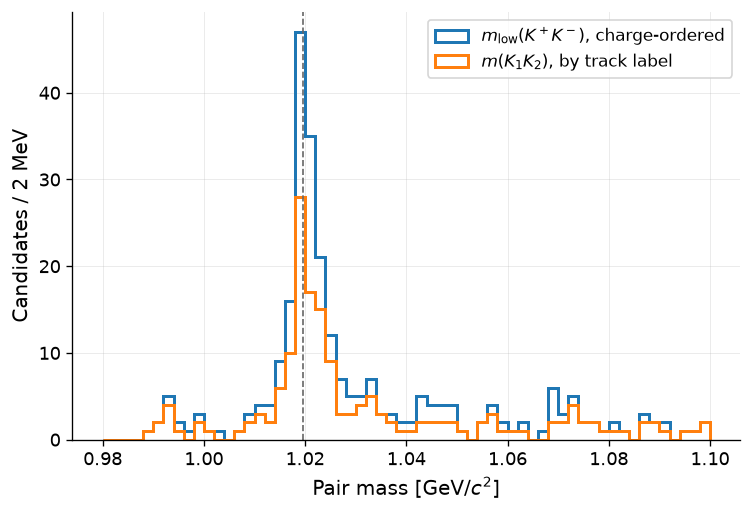

Candidates within 12 MeV of the phi mass: 167 charge-ordered, 101 by track label


In [5]:
phi_edges = np.linspace(0.98, 1.10, 61)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.hist(np.sqrt(analysis_df[OPPOSITE_SIGN_LOW]), bins=phi_edges, histtype="step", lw=1.8,
        label=r"$m_{\mathrm{low}}(K^+K^-)$, charge-ordered")
ax.hist(np.sqrt(analysis_df["m_K1K2_sq"]), bins=phi_edges, histtype="step", lw=1.8,
        label=r"$m(K_1K_2)$, by track label")
ax.axvline(1.0195, color="0.4", ls="--", lw=1)
ax.set_xlabel(r"Pair mass [GeV$/c^2$]")
ax.set_ylabel("Candidates / 2 MeV")
ax.legend()
fig.tight_layout()
plt.show()

in_phi = lambda m: np.abs(m - 1.0195) < 0.012
print(f"Candidates within 12 MeV of the phi mass: "
      f"{in_phi(np.sqrt(analysis_df[OPPOSITE_SIGN_LOW])).sum()} charge-ordered, "
      f"{in_phi(np.sqrt(analysis_df['m_K1K2_sq'])).sum()} by track label")

## Dalitz plots

A two-dimensional histogram is used instead of a raw scatter plot so dense regions remain readable. The colorbar gives the number of selected candidates in each bin.

In [6]:
def plot_dalitz_hist2d(ax, df, title, bins=60):
    hist = ax.hist2d(df[OPPOSITE_SIGN_LOW], df[OPPOSITE_SIGN_HIGH], bins=bins, cmap="viridis", cmin=1)
    ax.set_xlabel(r"$m^2_{\mathrm{low}}(K^+K^-)$ [GeV$^2/c^4$]")
    ax.set_ylabel(r"$m^2_{\mathrm{high}}(K^+K^-)$ [GeV$^2/c^4$]")
    ax.set_title(title)
    ax.grid(False)
    return hist

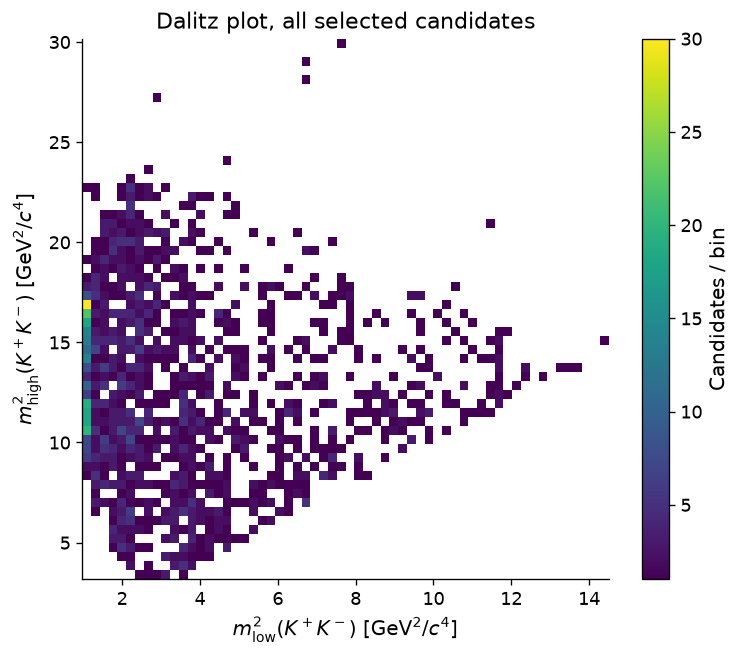

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
hist = plot_dalitz_hist2d(ax, analysis_df, "Dalitz plot, all selected candidates")
fig.colorbar(hist[3], ax=ax).set_label("Candidates / bin")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "dalitz_mKK_low_vs_high.png", dpi=300, bbox_inches="tight")
plt.show()

### $B^+$ and $B^-$ in the signal window

Because the charge-ordered variables are the same for a decay and its CP conjugate, the two charges can be compared point by point. The window $5245 < m(KKK) < 5325$ MeV$/c^2$ is the one used by the local-asymmetry study in `studies/dalitz/run_local_raw_asymmetry.py`, which does that comparison bin by bin.

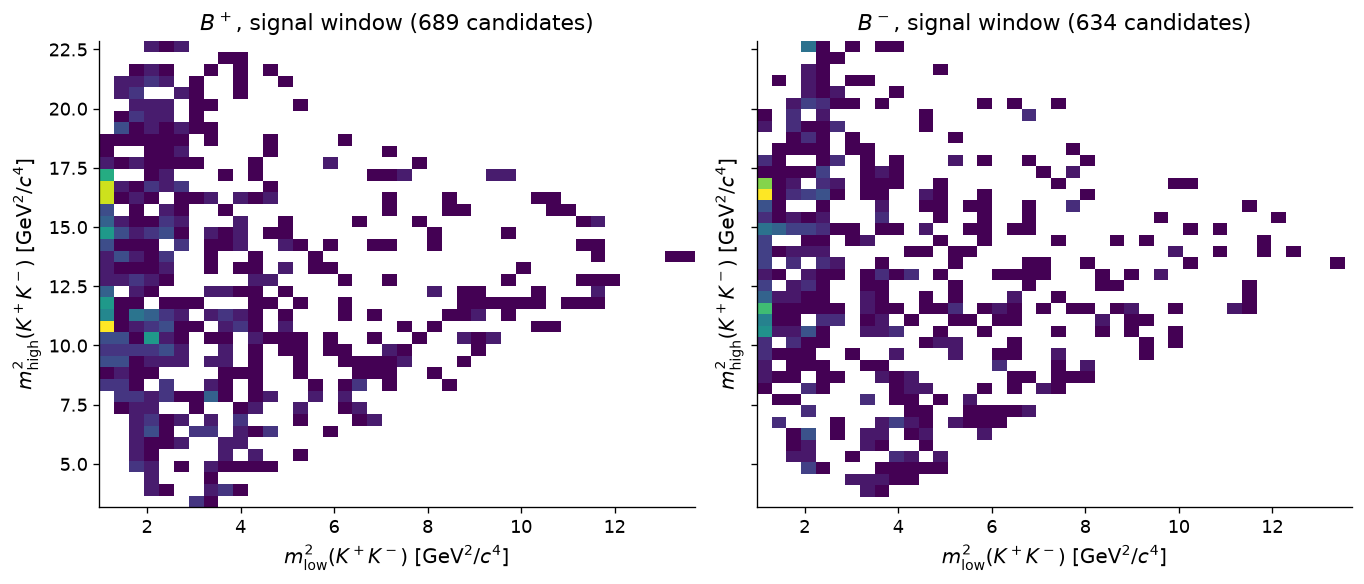

In [8]:
signal_window = analysis_df["B_mass"].between(5245.0, 5325.0)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0), sharex=True, sharey=True)
for ax, charge, label in zip(axes, (1, -1), (r"$B^+$", r"$B^-$")):
    sample = analysis_df[signal_window & (analysis_df["total_charge"] == charge)]
    plot_dalitz_hist2d(ax, sample, f"{label}, signal window ({len(sample)} candidates)", bins=40)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "dalitz_mKK_low_vs_high_by_charge.png", dpi=300, bbox_inches="tight")
plt.show()

## Interpretation

The charge-ordered Dalitz plot shows the phase-space population of the selected candidates, with the $\phi(1020)$ band at $m^2_{\mathrm{low}} \approx 1.04$ GeV$^2/c^4$ as the clearest resonant structure. The $B^+$ and $B^-$ maps are directly comparable; the quantitative comparison, with its look-elsewhere treatment, is done by the local-asymmetry study. A realistic amplitude analysis would in addition subtract backgrounds, correct efficiency variations across the plane, and model resonant components explicitly.